<a href="https://colab.research.google.com/github/Piloto6NoNo/Ejercicios_faciles_py1/blob/main/Practica1_Se%C3%B1ales_ASV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#preparacion de bio señal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fs = 100 # Frecuencia de muestre: 100 muestas por segundo
duracion = 10 # Duracion = 10 segundos
frecuencia = 1.2 #frecuencia principal de la señal

#vector de tiempo
t = np.arange (0, duracion, 1/fs)

#Generador aleatorio reproducible
rng = np.random.default_rng(42)

#Señal simulada con componente principal, componente secundario y ruido
senal = (
    1.5 * np.sin(2 * np.pi * frecuencia * t) #componente principal, señal de onda rápida y débil
    + 0.4 * np.sin(2 * np.pi * 3 * t)#Componente secundaria. señal de onda más rapida y debil con amplitud 0.4 y frecuencia 3.0Hz
    + rng.normal(0, 0.25, len(t))#Ruido blanco (modela las imperecciiones del mundo real utilizando la distribucion normal con medioa 0 ds 0.25)
)

#Guardar en una tabla
datos = pd.DataFrame({
    "tiempo_s": t,
    "amplitud": senal
})

print("Numero de muestras:", len(datos))
print("Frecuencia de muestreo:", fs, "Hz")
print("Duración", len (datos) / fs, "segundos")

display(datos.head())

Numero de muestras: 1000
Frecuencia de muestreo: 100 Hz
Duración 10.0 segundos


,tiempo_s,amplitud
0,0.00,0.076179
1,0.01,-0.072053
2,0.02,0.560201
3,0.03,0.785878
4,0.04,0.231622


In [3]:
#Actividad 1. Caracteristicas en el tiempo

#1. extraer señal

x= datos ["amplitud"].to_numpy()

#2. media, Nivel promedio de la señal

media = np.mean(x)

#3. RMS: Magnitud efectiva de la señal

rms = np.sqrt(np.mean(x**2))

#4. Amplitud máxima y mínima
maximo = np.max(x)
minimo = np.min(x)

#5. Obtener amplitud pico a pico

pico_a_pico = maximo - minimo

#desviación estándar
desviacion= np.std(x)

#Energia discreta de la ventana
energia = np.sum(x**2)

#Potencia media
potencia_media = np.mean(x**2)

print("Caracteristicas en el tiempo")
print(f"media:              {media:.4f}")
print(f"RMS:                {rms:.4f}")
print(f"Máximo:             {maximo:.4f}")
print(f"Mínimo:             {minimo:.4f}")
print(f"Amplitud pico a pico:{pico_a_pico:.4f}")
print(f"Desviación estandar:{desviacion:.4f}")
print(f"Energia discreta:{energia:.4f}")
print(f"Potencia media:{potencia_media:.4f}")




Caracteristicas en el tiempo
media:              -0.0072
RMS:                1.1372
Máximo:             2.3752
Mínimo:             -2.3152
Amplitud pico a pico:4.6904
Desviación estandar:1.1372
Energia discreta:1293.2612
Potencia media:1.2933


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
fs = 100
duracion = 10
t = np.arange(0, duracion, 1 /fs)
rng = np.random.default_rng(42)
x = (
    1.5 * np.sin(2 * np.pi *4.2 *t)
    + 0.4 * np.sin( 2 *np.pi *3 *t)
    +rng.normal(0,25, len(t))
)
inicio = 2
fin = 6
mascara = (t >= inicio) & (t < fin)
t_ventana = t[mascara]
x_ventana = x[mascara]
media_ventana = np.mean(x_ventana)
print("Variable t_ventana creada correctamente")
print("Número de meustras", len(t_ventana))
print("Media", round(media_ventana,4))








Variable t_ventana creada correctamente
Número de meustras 400
Media -0.617


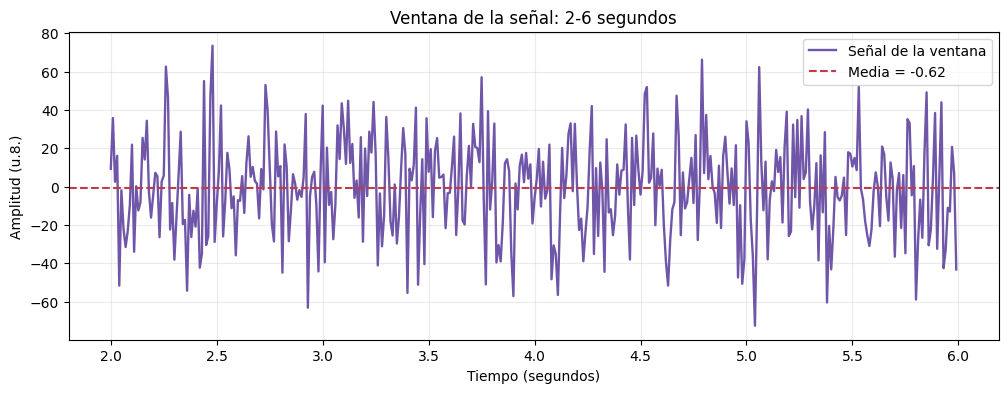

In [ ]:
from matplotlib import lines
#Generar gráfico de la activdad temporal

plt.figure(figsize=(12,4))

plt.plot (
    t_ventana,
    x_ventana,
    color = "#7056A8",
    linewidth=1.7,
    label = "Señal de la ventana"
)

plt.axhline(
    y=media_ventana,
    color="#C23B4A",
    linestyle="--",
    label=f"Media = {media_ventana:.2f}"
)

plt.title(f"Ventana de la señal: {inicio}-{fin} segundos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud (u.8.)")
plt.grid(alpha=0.25)
plt.legend()
plt.show()



In [ ]:
#"1. ¿Qué representa la señal de la media?
#Representa el valor promedio de la señal. Si la señal tiene valores positivos y
#negativos que se compensan entre sí, la media puede ser cercana a cero.#

#2. ¿Por qué el RMS no se anula cuando hay valores positivos y negativos?
#Porque el RMS eleva al cuadrado todos los valores antes de calcular el promedio
#y obtener la raíz cuadrada. Al elevarlos al cuadrado, todos se vuelven positivos,
#por lo que no se cancelan entre sí. El RMS representa la magnitud o energía
#efectiva de la señal.

#3. ¿Cuántos eventos se detectaron?
#El número de eventos detectados depende de los resultados del análisis de la
#señal y del criterio de detección utilizado. Se debe consultar el conteo de
#eventos obtenido en el código.

#4. ¿Cuál es el intervalo promedio entre tiempo_pico?
#Se calcula como el promedio de las diferencias entre los tiempos de picos
#consecutivos. Por ejemplo, si los picos ocurren en 1, 2 y 3 segundos, el
#intervalo promedio es de 1 segundo.

#5. ¿Cuál es la frecuencia de indice_dominante?
#Corresponde a la frecuencia asociada al índice de mayor amplitud en el espectro
#de frecuencias. Para conocer su valor exacto, es necesario revisar el resultado
#del análisis espectral.

#6. ¿Qué cambia si se analiza solamente una ventana de 2 a 6 segundos?
#Se analiza únicamente un fragmento de cuatro segundos de la señal. Esto puede
#cambiar la media, el RMS, el número de eventos detectados y el espectro de
#frecuencias, ya que los cálculos se realizan con menos datos.

#7. ¿La frecuencia dominante coincide con los 1.2 Hz usados para generar la señal?
#Debería ser aproximadamente 1.2 Hz, si esa es la frecuencia principal de la
#señal generada. Sin embargo, puede haber pequeñas diferencias debido a la
#duración de la ventana analizada, la resolución de la FFT y la presencia de
#ruido u otras frecuencias.

ANÁLISIS DE EVENTOS
Número de picos: 12
Tiempo de los picos: [0.13 1.08 1.8  2.73 3.44 4.43 5.19 6.06 6.76 7.73 8.46 9.41]
Intervalos: [0.95 0.72 0.93 0.71 0.99 0.76 0.87 0.7  0.97 0.73 0.95]
Intervalo promedio: 0.844 segundos
Ritmo estimado: 71.12 eventos/minuto


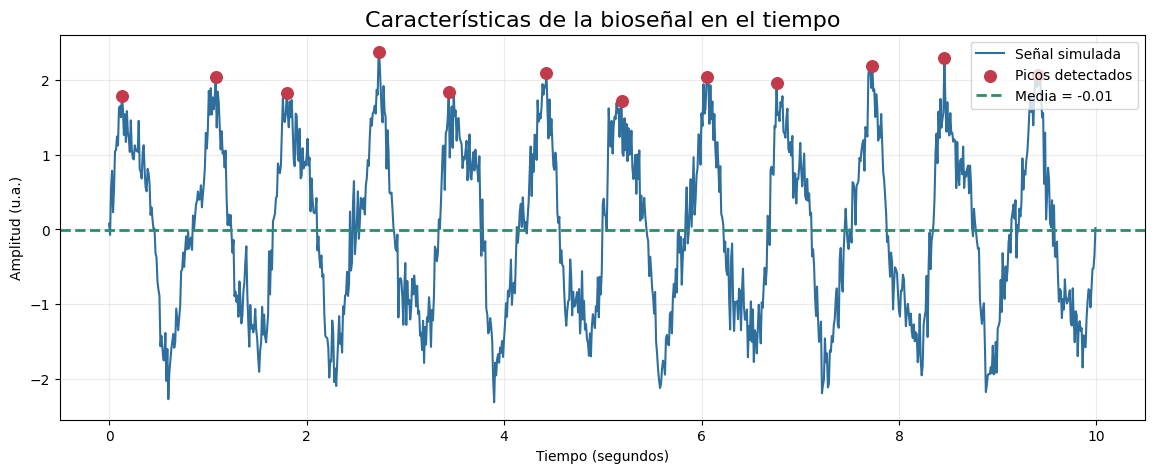

Ventana analizada: 2 a 6 segundos
Media: -0.0623
RMS: 1.1141
Amplitud pico a pico: 4.6904


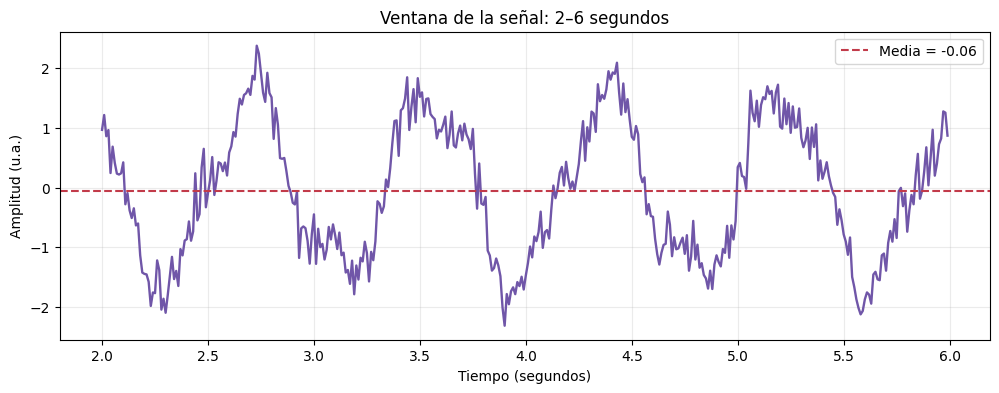

Frecuencia dominante: 1.172 Hz


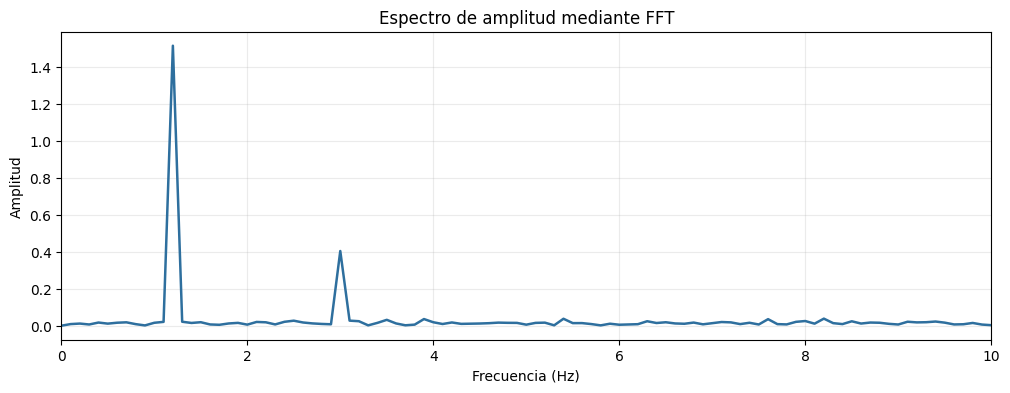

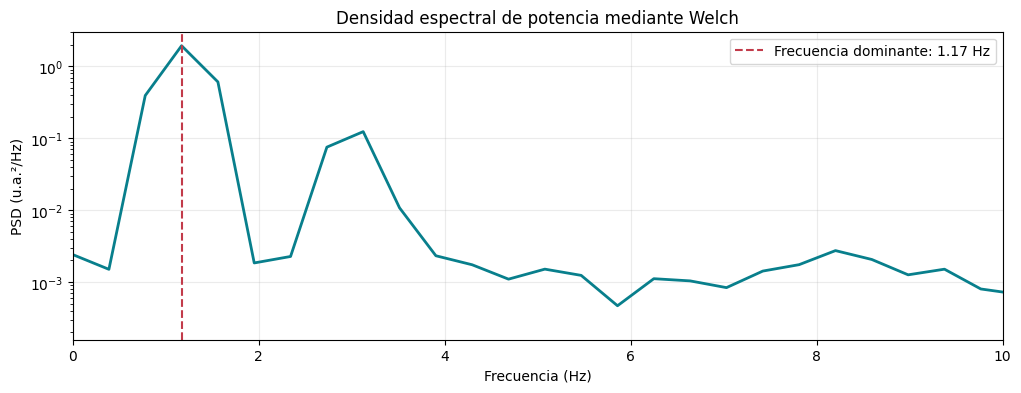

In [4]:
#Detectar pilcos e intervalos

from scipy.signal import find_peaks

# Separación mínima entre picos
# 0.5 segundos multiplicados por la frecuencia de muestreo
distancia_minima = int(0.5 * fs)

# Detectar picos
indices_picos, propiedades = find_peaks(
    x,
    distance=distancia_minima,
    prominence=0.8
)

# Tiempo en el que aparece cada pico
tiempo_picos = t[indices_picos]

# Intervalos entre picos consecutivos
intervalos = np.diff(tiempo_picos)

# Frecuencia o ritmo estimado
if len(intervalos) > 0:
    intervalo_promedio = np.mean(intervalos)
    ritmo_por_minuto = 60 / intervalo_promedio
else:
    intervalo_promedio = np.nan
    ritmo_por_minuto = np.nan

print("ANÁLISIS DE EVENTOS")
print("Número de picos:", len(indices_picos))
print("Tiempo de los picos:", np.round(tiempo_picos, 3))
print("Intervalos:", np.round(intervalos, 3))
print(f"Intervalo promedio: {intervalo_promedio:.3f} segundos")
print(f"Ritmo estimado: {ritmo_por_minuto:.2f} eventos/minuto")

plt.figure(figsize=(14, 5))

# Señal completa
plt.plot(
    t,
    x,
    color="#2E6F9E",
    linewidth=1.5,
    label="Señal simulada"
)

# Picos detectados
plt.scatter(
    tiempo_picos,
    x[indices_picos],
    color="#C23B4A",
    s=70,
    zorder=3,
    label="Picos detectados"
)

# Línea de la media
plt.axhline(
    media,
    color="#2A8C70",
    linestyle="--",
    linewidth=2,
    label=f"Media = {media:.2f}"
)

plt.title("Características de la bioseñal en el tiempo", fontsize=16)
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud (u.a.)")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

# Analizar solamente una ventana entre 2 y 6 segundos
inicio = 2
fin = 6

mascara = (t >= inicio) & (t < fin)

t_ventana = t[mascara]
x_ventana = x[mascara]

media_ventana = np.mean(x_ventana)
rms_ventana = np.sqrt(np.mean(x_ventana**2))
pico_pico_ventana = np.ptp(x_ventana)

print(f"Ventana analizada: {inicio} a {fin} segundos")
print(f"Media: {media_ventana:.4f}")
print(f"RMS: {rms_ventana:.4f}")
print(f"Amplitud pico a pico: {pico_pico_ventana:.4f}")

plt.figure(figsize=(12, 4))

plt.plot(
    t_ventana,
    x_ventana,
    color="#7056A8",
    linewidth=1.7
)

plt.axhline(
    media_ventana,
    color="#C23B4A",
    linestyle="--",
    label=f"Media = {media_ventana:.2f}"
)

plt.title(f"Ventana de la señal: {inicio}–{fin} segundos")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud (u.a.)")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

from scipy.signal import welch

# Eliminar la media antes del análisis frecuencial
x_centrada = x - np.mean(x) #Limpiar espectro para concentrarme solo en las oscilaciones reales.

# Transformada rápida de Fourier  fft # para transformar señales con números reales, devolverá nýmero complejos que cotienen información de magnitud y fase
fft_valores = np.fft.rfft(x_centrada)
fft_frecuencias = np.fft.rfftfreq(len(x_centrada), d=1/fs) #calcula exactamente a que frecuencias en (hz) correspónde cada valor obtenido en la FFT, basada en fs
fft_amplitud = 2 * np.abs(fft_valores) / len(x_centrada) #convertir los numeros completos qu me dio FFT en amplitudes reales y físicas mediante el valor absoluto
                                                        #multiplicamos por 2 y se divide por la longitud de la señal para normalizar los valores y hacerlos que coincidan
                                                        #con las palitudes originales de nuestras senoides

# Densidad espectral de potencia con Welch: es una técnica avanzada para estimar la potencia de las frecuencias de una señal cuando esta contiene ruido
frecuencias_psd, psd = welch(
    x_centrada,
    fs=fs,
    nperseg=256, #número de muestras
    noverlap=128 #indicame que segmentos se superponene a la mitad para no perder infoermación en los bortdes. R= un cuarva mas suave y limpi8ua que una FFT standar
)

# Frecuencia dominante
indice_dominante = np.argmax(psd)
frecuencia_dominante = frecuencias_psd[indice_dominante]

print(f"Frecuencia dominante: {frecuencia_dominante:.3f} Hz")

plt.figure(figsize=(12, 4))

plt.plot(
    fft_frecuencias,
    fft_amplitud,
    color="#2E6F9E",
    linewidth=1.8
)

plt.xlim(0, 10)
plt.title("Espectro de amplitud mediante FFT")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(12, 4))

plt.semilogy(
    frecuencias_psd,
    psd,
    color="#087F8C",
    linewidth=2
)

plt.axvline(
    frecuencia_dominante,
    color="#C23B4A",
    linestyle="--",
    label=f"Frecuencia dominante: {frecuencia_dominante:.2f} Hz"
)

plt.xlim(0, 10)
plt.title("Densidad espectral de potencia mediante Welch")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("PSD (u.a.²/Hz)")
plt.grid(alpha=0.25)
plt.legend()
plt.show()